In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Partie 1 - Analyse préliminaire

   PassengerId  Survived  Pclass      Name  \
0          299         1       1  Saalfeld   
1          300         1       1    Baxter   
2          301         1       3     Kelly   
3          302         1       3     McCoy   
4          303         0       3   Johnson   

                                   FullName     Sex   Age  SibSp  Parch  \
0                               Mr. Adolphe    male   NaN      0      0   
1   Mrs. James (Helene DeLaudeniere Chaput)  female  50.0      0      1   
2           Miss. Anna Katherine Annie Kate  female   NaN      0      0   
3                               Mr. Bernard    male   NaN      2      0   
4                    Mr. William Cahoone Jr    male  19.0      0      0   

     Ticket      Fare    Cabin Embarked  
0     19988   30.5000     C106        S  
1  PC 17558  247.5208  B58 B60        C  
2      9234    7.7500      NaN        Q  
3    367226   23.2500      NaN        Q  
4      LINE    0.0000      NaN        S  


Types des variable

/var/folders/sy/l78029ys4fn21j0ftgwj4tzw0000gn/T/ipykernel_9110/1798443934.py:15: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  df_plot.hist(ax=ax, bins=15, edgecolor='black')


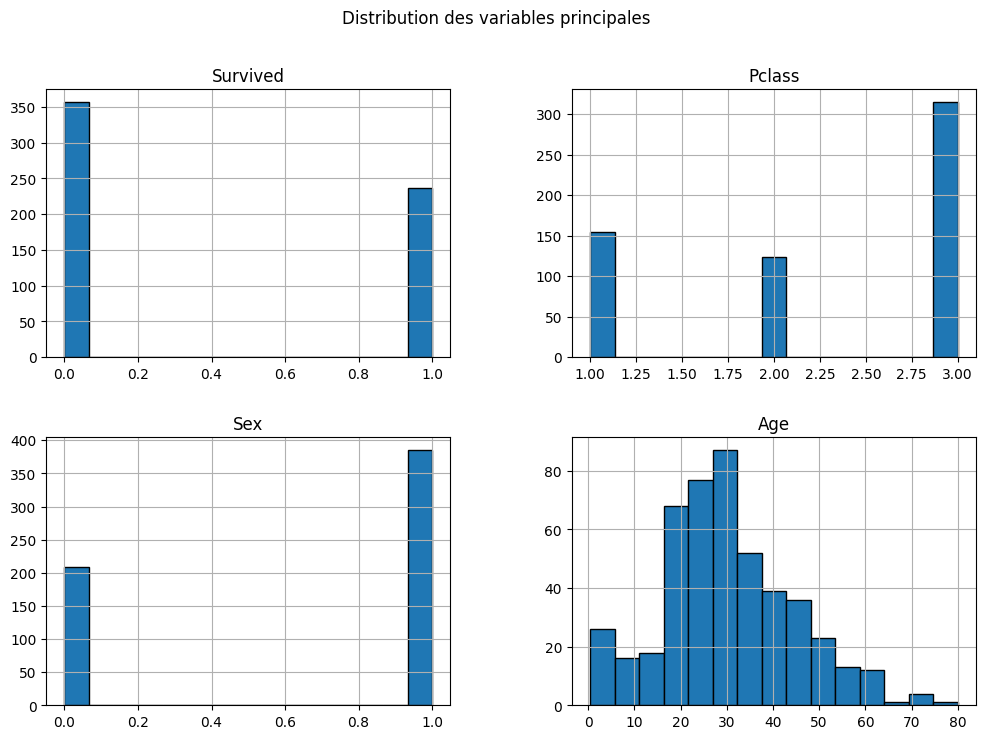



Proportion de valeurs manquantes:
PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
FullName        0.000000
Sex             0.000000
Age            20.236088
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          75.885329
Embarked        0.168634
dtype: float64


In [69]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("titanic_train.csv")
print(df.head())
print(f"\n\nTypes des variables :\n{df.dtypes}")
print("\n\n Info :")
df.info()
print(f"\n\nStatistiques descriptives :\n{df.describe()}")

var_pcp = ['Survived', 'Pclass', 'Sex', 'Age']
df_plot = df[var_pcp].copy()
df_plot['Sex'] = df_plot['Sex'].map({'female': 0, 'male': 1})
fig, ax = plt.subplots(figsize=(12, 8))
df_plot.hist(ax=ax, bins=15, edgecolor='black')
plt.suptitle('Distribution des variables principales')
plt.show()

print("\n\nProportion de valeurs manquantes:")
print(df.isna().mean() * 100)

nombre de survivants :  236
nombre de décédés :  357


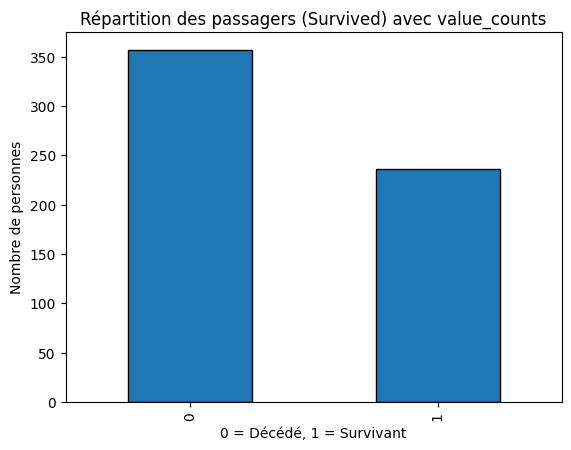

pourcentage de survivants :  39.79763912310287
pourcentage de décédés :  60.20236087689713


In [70]:
survecu = 0

for i in range(len(df)):
    if df["Survived"][i] == 1:
        survecu += 1


decedes = len(df["Survived"]) - survecu

print("nombre de survivants : ", survecu)
print("nombre de décédés : ", decedes)

df['Survived'].value_counts().plot(kind='bar', edgecolor='black')

plt.title('Répartition des passagers (Survived) avec value_counts')
plt.xlabel('0 = Décédé, 1 = Survivant')
plt.ylabel('Nombre de personnes')
plt.show()

print("pourcentage de survivants : ", (survecu * 100)/  len(df["Survived"]))
print("pourcentage de décédés : ", (decedes * 100)/  len(df["Survived"]))

# Partie 2 - Les femmes et les enfants d'abord

In [71]:
# on regarde que la colonne qui nous intéresse -> Survived
taux_survie_sexe = df.groupby("Sex")["Survived"].mean() * 100
print(taux_survie_sexe)

Sex
female    75.961538
male      20.259740
Name: Survived, dtype: float64


Interprétation : on voit qu'il y a une grande différence entre le taux des hommes et celui des femmes, près de 76 % des femmes ont su Ça fait écho à la phrase "les femmes et les enfants d'abord" -> le sexe = c'ets une variable explicative impoortante pour la prédiction de la survie.

In [72]:
import numpy as np

df['Child'] = np.where(df['Age'] < 18, 'child', 'adult')

print(df.groupby('Child')['Survived'].mean() * 100)

Child
adult    37.404580
child    57.971014
Name: Survived, dtype: float64


Interpréation : Ici aussi, on voit qu'il y a une différence significative entre le taux de survie des enfants et celui des adultes, avec près de 58 % des enfants qui ont survécu contre seulement 37 % des adultes. Tout comme le sexe, la catégorie d'âge est donc une variable explicative importante pour la prédiction de la survie.

On voit que ça fait écho à l'expression "les femmes et les enfants d'abord"

Question 3 : hypothèse potentiellement biaisée : On suppose que tous les passagers avec un âge manquant sont des adultes

Pour corriger ce biais on peut ignorer les passagers dont l’âge est manquant

In [73]:
import numpy as np
df['Child_corrigé'] = np.where(df['Age'] < 18, 'child', 'adult')
df['Child_corrigé'] = df['Child_corrigé'].where(df['Age'].notna())

taux_survie_age_corrige = df.groupby('Child_corrigé')['Survived'].mean() * 100
print(taux_survie_age_corrige)

Child_corrigé
adult    40.346535
child    57.971014
Name: Survived, dtype: float64


Interprétation : Le taux de survie des adultes passe d'environ 37,4 % à 40,3 % après avoir retiré les valeurs manquantes et celui des enfants ne change pas donc en corrigeant ce biais, on obtient une vision plus juste : l'écart de survie entre les enfants et les adultes est moins importante même si la priorité donnée aux enfants reste vraie.

In [74]:
taux = df.groupby(['Child_corrigé', 'Sex'])['Survived'].mean() * 100
print(taux)

Child_corrigé  Sex   
adult          female    78.321678
               male      19.540230
child          female    75.000000
               male      43.243243
Name: Survived, dtype: float64


En croisant l'âge et le sexe, on constate que "Les femmes et les enfants d'abord" a été appliquée avec une forte priorisation envers les femmes, qu'elles soient adultes (78,3 %) ou enfants (75 %).

Chez les passagers masculins, l'enfant a plus que doublé les chances de survie (43,2 % pour les garçons contre seulement 19,5 % pour les hommes adultes)

In [75]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OrdinalEncoder

test = pd.read_csv("titanic_test.csv")

df['Child'] = np.where(df['Age'].isna(), 'inconnu', np.where(df['Age'] < 18, 'child', 'adult'))
test['Child'] = np.where(test['Age'].isna(), 'inconnu', np.where(test['Age'] < 18, 'child', 'adult'))

# variables explicatives
X_train = df[['Sex', 'Child']]
X_test = test[['Sex', 'Child']]
y_train = df['Survived']

# encodage avec OrdinalEncoder
encoder = OrdinalEncoder()
X_train = encoder.fit_transform(X_train)
X_test = encoder.transform(X_test)

In [76]:
print("Correspondance des catégories (l'indice correspond à l'entier encodé 0, 1, 2 etc.) :")
for i, col in enumerate(encoder.feature_names_in_):
    print(f"Variable '{col}' : {encoder.categories_[i]}")

Correspondance des catégories (l'indice correspond à l'entier encodé 0, 1, 2 etc.) :
Variable 'Sex' : ['female' 'male']
Variable 'Child' : ['adult' 'child' 'inconnu']


En utilisant OrdinalEncoder on a ajusté (fit) le dictionnaire de codage que sur les données d'apprentissage (X_train), puis on a appliqué (transform) ce dictionnaire sur l'ensemble de validation (X_test) donc les deux ensembles ont le même codage (par exemple, female est encodé par 0 et male par 1 dans les deux DataFrame)

In [77]:
from sklearn.naive_bayes import CategoricalNB
import numpy as np

classifier = CategoricalNB()
classifier.fit(X_train, y_train)

print("Classes :", classifier.classes_)
print("class_log_prior_ :\n", classifier.class_log_prior_)
print("feature_log_prob_ pour le sexe :\n", classifier.feature_log_prob_[0])
print("feature_log_prob_ pour l'age :\n", classifier.feature_log_prob_[1])

Classes : [0 1]
class_log_prior_ :
 [-0.50745862 -0.92136259]
feature_log_prob_ pour le sexe :
 [[-1.95149676 -0.15322261]
 [-0.40336647 -1.10282282]]
feature_log_prob_ pour l'age :
 [[-0.39716631 -2.48490665 -1.40876722]
 [-0.37659712 -1.76289149 -1.95010303]]


classifier.classes_ : les étiquettes de la variable cible Survived
- [0 1] signifie que le modèle cherche à prédire la classe 0 (décédé) et la classe 1 (survivant)
- classifier.class_log_prior_ : le log de la probabilité a priori de chaque classe P(Y) donc par ex si on applique la fonction exponentielle on aura les proportions de la question 1 : environ 60,2 % de morts et 39,8 % de survivants
- classifier.feature_log_prob_ : log des probabilités conditionnelles P(X_i \vert{} Y). Par exemple, pour la variable Sex (indice 0), ça donne la probabilité d'être une femme sachant qu'on a survécu P(Sex=female \vert{} Survived=1), et d'être un homme sachant qu'on a survécu P(Sex=male \vert{} Survived=1)


Ces probabilités permettent au modèle de faire le lien avec les taux de survie croisés calculés aux questions précédentes


Le modèle est  naïf car il supprose l'indépendance conditionnelle des variables explicatives. Il suppose que sachant si un passager a survécu ou non, son sexe n'a aucune influence sur sa catégorie d'âge

In [78]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_test = test['Survived']
y_pred = classifier.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy : {accuracy * 100} %")

cm = confusion_matrix(y_test, y_pred)
print("\nMatrice de confusion :")
print(cm)

Accuracy : 79.19463087248322 %

Matrice de confusion :
[[161  31]
 [ 31  75]]


# Partie 3 : Taux de survie selon la classe sociale

In [79]:
taux_pclass = df.groupby('Pclass')['Survived'].mean() * 100
print(taux_pclass)

Pclass
1    68.831169
2    50.000000
3    21.587302
Name: Survived, dtype: float64


Interprétation : plus la classe sociale du passager est élevée, plus ses chances de survie sont fortes

Un passager en 1ère classe avait plus de 3x plus de chances de survivre qu'un passager en 3ème classe

In [80]:
import numpy as np
import pandas as pd

bins = [0, 10, 20, 30, np.inf]
labels = ['<10', '10-20', '20-30', '30+']

print("Convention retenue : intervalles fermés à gauche, ouverts à droite ex : [a, b[\n")
df['Fare2'] = pd.cut(df['Fare'], bins=bins, right=False, labels=labels)
df['Fare2'] = df['Fare2'].cat.add_categories('NA').fillna('NA')

test['Fare2'] = pd.cut(test['Fare'], bins=bins, right=False, labels=labels)
test['Fare2'] = test['Fare2'].cat.add_categories('NA').fillna('NA')

Convention retenue : intervalles fermés à gauche, ouverts à droite ex : [a, b[



In [81]:
contingence = pd.crosstab(df['Pclass'], df['Fare2'], margins=True)
print(contingence)

Fare2   <10  10-20  20-30  30+  All
Pclass                             
1         5      0     24  125  154
2         5     63     38   18  124
3       213     51     28   23  315
All     223    114     90  166  593


Question 3.3 : Les variables Pclass et Fare2 ne sont pas indépendantes :
L'analyse des proportions par ligne dans le tableau de contingence montre une dépendance très importante :
- 1ère classe : 125 sur 154 passagers ont un billet dans la tranche 30+, et seulement 3,2 % ont un billet <10
- 2ème classe : la plupart sont dans les tranches d'indexation moyenne 10-20 (50 %) et dans la tranche 20-30 (30,6 %)
- 3ème classe : 213 sur 315 passagers ont un billet à bas coût <10, et très peu ont un billet 30+

La distribution du tarif Fare2 varie selon la classe sociale Pclass.

(+ cette forte relation de dépendance implique que Fare2 et Pclass donnent des informations sans doute redondantes pour le classifieur naïf bayésien)

In [82]:
taux_fare2 = df.groupby('Fare2')['Survived'].mean() * 100
print(taux_fare2)

Fare2
<10      17.040359
10-20    43.859649
20-30    44.444444
30+      65.060241
NA             NaN
Name: Survived, dtype: float64


/var/folders/sy/l78029ys4fn21j0ftgwj4tzw0000gn/T/ipykernel_9110/134768794.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  taux_fare2 = df.groupby('Fare2')['Survived'].mean() * 100


Relation positive ++ : le taux de survie augmente fortement avec le tarif du billet

Ce qui confirme la dépendance avec la variable Pclass qu'on a observé au tableau de contingence

La modalité NA est vide car il n'y a aucun tarif manquant dans l'ensemble d'apprentissage.

In [83]:
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import OrdinalEncoder

X_train_2 = df[['Pclass', 'Fare2']]
y_train_2 = df['Survived']

X_test_2 = test[['Pclass', 'Fare2']]
y_test_2 = test['Survived']

# on encode à nv avec ordinalencoder
encoder_2 = OrdinalEncoder()
X_train_2_encoded = encoder_2.fit_transform(X_train_2)
X_test_2_encoded = encoder_2.transform(X_test_2)

clf2 = CategoricalNB()
clf2.fit(X_train_2_encoded, y_train_2)

y_pred_2 = clf2.predict(X_test_2_encoded)



In [84]:
accuracy2 = accuracy_score(y_test_2, y_pred_2)
print(f"Accuracy : {accuracy2 * 100} %")
print("\nMatrice de confusion :\n", confusion_matrix(y_test_2, y_pred_2))

Accuracy : 61.07382550335571 %

Matrice de confusion :
 [[127  65]
 [ 51  55]]


In [85]:
if accuracy > accuracy2:
    diff = (accuracy - accuracy2) * 100
    print(f"Le modèle 1 (Sex, Child) est plus performant que le modèle 2")
elif accuracy2 > accuracy:
    diff = (accuracy2 - accuracy) * 100
    print(f"Le modèle 2 (Pclass, Fare2) est plus performant que le modèle 1")
else:
    print("Les deux modèles obtiennent la même accuracy.")

Le modèle 1 (Sex, Child) est plus performant que le modèle 2


Même so Pclass et Fare2 sont de bons indicateurs socio-économiques, le sexe et l'âge sont plus prédictif sur la survie des passagers lors du naufrage, autrement dit, la classe sociale et le prix du billet seuls sont moins discriminants pour prédire la survie que les informations sur le sexe et l’âge des passagers.

# Partie 4 : Modèles combinés


In [86]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

variables = ['Sex', 'Child', 'Pclass', 'Fare2']

X_train_3 = df[variables]
y_train = df['Survived']

X_test_3 = test[variables]
y_test = test['Survived']

# on fait encore avec ordinalencoder (fit sur le train + transform sur test)
encoder_3 = OrdinalEncoder()
X_train_3_encoded = encoder_3.fit_transform(X_train_3)
X_test_3_encoded = encoder_3.transform(X_test_3)

In [87]:
classifier_3 = CategoricalNB()
classifier_3.fit(X_train_3_encoded, y_train)

CategoricalNB()

In [88]:
y_pred_3 = classifier_3.predict(X_test_3_encoded)

accuracy3 = accuracy_score(y_test, y_pred_3)
cm_3 = confusion_matrix(y_test, y_pred_3)
classif_report = classification_report(y_test, y_pred_3, target_names=['Décédé (0)', 'Survivant (1)'])

print(f"Accuracy du modèle 3 : {accuracy3 * 100} %\n")
print("Matrice de confusion :\n", cm_3)
print("\nRapport de classification :\n", classif_report)

Accuracy du modèle 3 : 68.79194630872483 %

Matrice de confusion :
 [[144  48]
 [ 45  61]]

Rapport de classification :
                precision    recall  f1-score   support

   Décédé (0)       0.76      0.75      0.76       192
Survivant (1)       0.56      0.58      0.57       106

     accuracy                           0.69       298
    macro avg       0.66      0.66      0.66       298
 weighted avg       0.69      0.69      0.69       298



Récap accuracies
Modèle 1 (Sex, Child)          : 79.19 %
Modèle 2 (Pclass, Fare2)       : 61.07 %
Modèle 3 (Child, Sex, Pclass, Fare2) : 68.79 %

Le meilleur modèle sur le jeu de test est : Modèle 1 (Sex, Child)


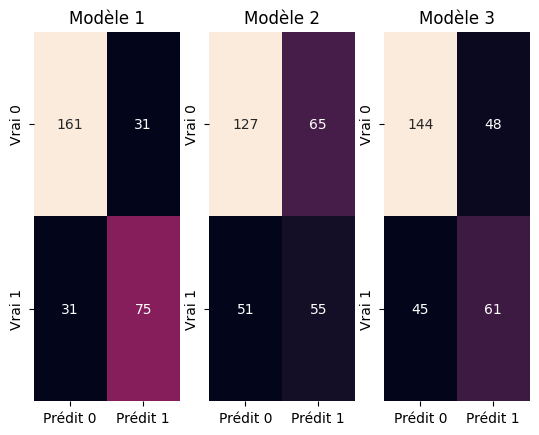

In [89]:
modeles = {
    "Modèle 1 (Sex, Child)": accuracy,
    "Modèle 2 (Pclass, Fare2)": accuracy2,
    "Modèle 3 (Child, Sex, Pclass, Fare2)": accuracy3,
}

print("Récap accuracies")
for nom, acc in modeles.items():
    print(f"{nom:<30} : {acc * 100:.2f} %")

meilleur_modele = max(modeles, key=modeles.get)
print(f"\nLe meilleur modèle sur le jeu de test est : {meilleur_modele}")


fig, axes = plt.subplots(1, 3)
for ax, (nom, m) in zip(axes, [("Modèle 1", confusion_matrix(y_test, y_pred)),("Modèle 2", confusion_matrix(y_test_2, y_pred_2)),("Modèle 3", cm_3)]):
    sns.heatmap(m, annot=True, fmt='d', cbar=False, ax=ax, xticklabels=['Prédit 0', 'Prédit 1'], yticklabels=['Vrai 0', 'Vrai 1'])
    # format décimal sinon err
    ax.set_title(nom)
plt.show()

Interprétation : le modèle 3 a 68,8 % donc moins que le modèle 1 donc on ne peut pas dire que plus de variables = meilleur classifieur :
- le classifieur CategoricalNB suppose l'indépendance conditionnelle des variables sachant la cible or Pclass et Fare2 sont fortement dépendantes
- en multipliant les probabilités conditionnelles de Pclass et Fare2, le modèle surestime artificiellement leur poids

D'après la matrice de confusion, le modèle 1 fait 31 + 31 erreurs alors que le modèle 3 en fait 48 + 45, il se trompe donc plus aussi.

Le meilleur modèle est le 1.

In [90]:
df['Embarked'] = df['Embarked'].fillna('NA').astype(str).str.strip().replace({'': 'NA', 'nan': 'NA'})
# on sépare en 3 categ
df['SibSp2'] = pd.cut(df['SibSp'], bins=[-1, 0, 1, np.inf], labels=['0', '1', 'plusieurs']).astype(str)
df['Parch2'] = pd.cut(df['Parch'], bins=[-1, 0, 1, np.inf], labels=['0', '1', 'plusieurs']).astype(str)
df['Cabin2'] = np.where(df['Cabin'].fillna('').astype(str).str.strip() == '', 'NA', 'known')

#idem pour test :
test['Embarked'] = test['Embarked'].fillna('NA').astype(str).str.strip().replace({'': 'NA', 'nan': 'NA'})

test['SibSp2'] = pd.cut(test['SibSp'], bins=[-1, 0, 1, np.inf], labels=['0', '1', 'plusieurs']).astype(str)
test['Parch2'] = pd.cut(test['Parch'], bins=[-1, 0, 1, np.inf], labels=['0', '1', 'plusieurs']).astype(str)

test['Cabin2'] = np.where(test['Cabin'].fillna('').astype(str).str.strip() == '', 'NA', 'known')

In [91]:
variables_tot = ['Child', 'Sex', 'Pclass', 'Fare2', 'Embarked', 'SibSp2', 'Parch2', 'Cabin2']

X_train_4 = df[variables_tot].astype(str)
X_test_4 = test[variables_tot].astype(str)

encoder_4 = OrdinalEncoder()
X_train_4_encoded = encoder_4.fit_transform(X_train_4)
X_test_4_encoded = encoder_4.transform(X_test_4)

classifier_4 = CategoricalNB()
classifier_4.fit(X_train_4_encoded, y_train)

y_pred_4 = classifier_4.predict(X_test_4_encoded)

accuracy4 = accuracy_score(y_test, y_pred_4)
cm_4 = confusion_matrix(y_test, y_pred_4)

print(f"Accuracy du modèle 4 : {accuracy4 * 100} %\n")
print("Matrice de confusion :\n", cm_4)

Accuracy du modèle 4 : 68.45637583892618 %

Matrice de confusion :
 [[145  47]
 [ 47  59]]


In [92]:
var_a_add = ['Child', 'Sex', 'Pclass', 'Fare2']

for var in ['Embarked', 'SibSp2', 'Parch2', 'Cabin2']:
    cols = var_a_add + [var]

    enc = OrdinalEncoder()
    X_tr = enc.fit_transform(df[cols].astype(str))
    X_te = enc.transform(test[cols].astype(str))

    clf = CategoricalNB()
    clf.fit(X_tr, y_train)
    pred = clf.predict(X_te)

    print(f"Modèle 3 + variable {var} : {accuracy_score(y_test, pred) * 100} %")
    print(confusion_matrix(y_test, pred), "\n")

Modèle 3 + variable Embarked : 68.12080536912751 %
[[142  50]
 [ 45  61]] 

Modèle 3 + variable SibSp2 : 71.14093959731544 %
[[147  45]
 [ 41  65]] 

Modèle 3 + variable Parch2 : 69.79865771812081 %
[[144  48]
 [ 42  64]] 

Modèle 3 + variable Cabin2 : 69.79865771812081 %
[[150  42]
 [ 48  58]] 



Don on ajoute les variables une par une au modèle 3 (Child, Sex, Pclass, Fare2) pour isoler la contribution de chacune et on fait aussi le modèle 4 avec les 4 variables ajoutées directement toutes ensemble.

Initialiement on avait accuracy du modèle 3 = 68,79 %, avec : 

SibSp2 : 71,14 %
Parch2 : 69,80 %
Cabin2 : 69,80 %
Embarked : 68,12 %
Modèle 4 (toutes les variables) : 68,46 %

Donc SibSp2 est la variable qui apporte le plus d’information utile (on a +2,35 points d'accuracy) ce qui fait sens car voyager seul ou en petite famille change les chances de survie.
Au passage, Embarked n’apporte rien surement car le port d’embarquement est montre la classe sociale, qui est déjà prise en compte dans le modèle.

Mais le modèle 4 (68,46 %) est moins bon que chacun des modèles « 3 + une variable » car les variables sont redondantes et ne sont pas indépendantes sachant la survie donc pas d’hypothèse naïve possible.

Aucun de ces modèles est meilleur que le modèle 1 (79,19 %)

Conclusion : ajouter des variables n’améliore pas forcément le classifieur, le plus important c’est l’information nouvelle apportée

# Partie 5 : Synthèse et comparaison des modèles

In [93]:
cm_2 = confusion_matrix(y_test_2, y_pred_2)

print("Modèle 1 (Sex, Child)                  :", f"{accuracy * 100} %", "| faux positifs :", cm[0, 1], "| faux négatifs :", cm[1, 0])
print("Modèle 2 (Pclass, Fare2)               :", f"{accuracy2 * 100} %", "| faux positifs :", cm_2[0, 1], "| faux négatifs :", cm_2[1, 0])
print("Modèle 3 (Child, Sex, Pclass, Fare2)   :", f"{accuracy3 * 100} %", "| faux positifs :", cm_3[0, 1], "| faux négatifs :", cm_3[1, 0])
print("Modèle 4 (modèle 3 + 4 nouvelles var.) :", f"{accuracy4 * 100} %", "| faux positifs :", cm_4[0, 1], "| faux négatifs :", cm_4[1, 0])

Modèle 1 (Sex, Child)                  : 79.19463087248322 % | faux positifs : 31 | faux négatifs : 31
Modèle 2 (Pclass, Fare2)               : 61.07382550335571 % | faux positifs : 65 | faux négatifs : 51
Modèle 3 (Child, Sex, Pclass, Fare2)   : 68.79194630872483 % | faux positifs : 48 | faux négatifs : 45
Modèle 4 (modèle 3 + 4 nouvelles var.) : 68.45637583892618 % | faux positifs : 47 | faux négatifs : 47


1. Le modèle 1 (Sex, Child) avec 79,19 % de bonnes classifications est le meilleur modèle

2. Non par ex : les modèles 3 et 4 ont plus de variables mais font moins bien que le modèle 1 donc une variable n’améliore le classifieur que si elle apporte une information nouvelle.

3. Non par ex Pclass et Fare2 sont liées et SibSp2 et Parch2 mesurent la taille de la famille et Cabin2 dépend de la classe dnc il y a redondance de l'info : l'information est comptée plusieurs fois ce qui dégrade le modèle

4. Les variables ne sont pas indépendantes entre elles , beaucoup de valeurs manquantes (âge, cabine),la discrétisation fait perdre de l’information, le jeu de test reste petit (298 passagers) et le modèle ne capture pas les interactions (par exemple « femme en 3ᵉ classe »)